In [1]:
# Design of a mini GPT model for text generation using 20m Params

import jax
import jax.numpy as jnp
import flax.nnx as nnx

import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Create embedding layer   

class TokenAndPositionEmbedding(nnx.Module):
    def __init__(self, maxlen, vocab_size, embed_dim, *, rngs):
        self.token_emb = nnx.Embed(vocab_size, embed_dim, rngs=rngs)
        self.pos_emb = nnx.Embed(maxlen, embed_dim, rngs=rngs)

    def __call__(self, x):
        seq_len = x.shape[1]
        positions = jnp.arange(seq_len)[None, :]
        return self.token_emb(x) + self.pos_emb(positions)

In [ ]:
# Causal attention mask to prevent attending to future tokens
def causal_attention_mask(seq_len):
    return jnp.tril(jnp.ones((seq_len, seq_len)))
    

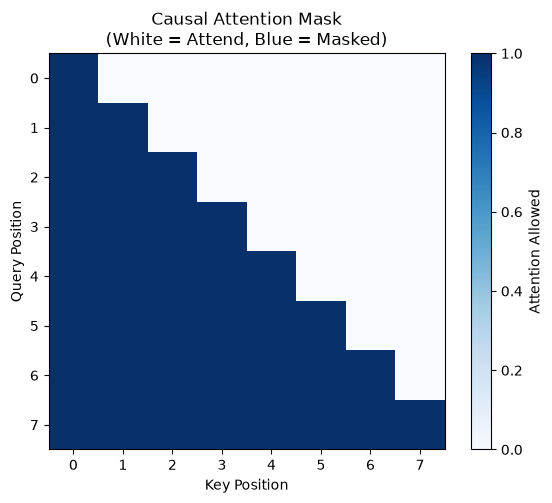

In [ ]:
# Visualize the causal attention mask
mask = causal_attention_mask(8)
plt.figure(figsize=(6, 5))
plt.imshow(mask, cmap='Blues', interpolation='nearest')
plt.xlabel('Key Position')
plt.ylabel('Query Position')
plt.title('Causal Attention Mask\n(White = Attend, Blue = Masked)')
plt.colorbar(label='Attention Allowed')
plt.tight_layout()
plt.show()

In [ ]:
# Transformer Block with Multi-Head Attention and Feedforward Network
class TransformerBlock(nnx.Module):

    def __init__(self, embed_dim, num_heads, ff_dim, *, rngs):
        self.attention = nnx.MultiHeadAttention(
            num_heads=num_heads,
            in_features=embed_dim,
            qkv_features=embed_dim,
            out_features=embed_dim,
            decode=False,
            rngs=rngs
        )
        
    def __call__(self, x, mask=None):
        attn_out = self.attention(x, mask=mask)
        x = x + attn_out
        return x

In [6]:
# Define the GPT model architecture

class MiniGPT(nnx.Module):

    def __init__(self, maxlen, vocab_size, embed_dim, num_heads,
                 feed_forward_dim, num_transformer_blocks, *, rngs):
        self.maxlen = maxlen
        self.embedding = TokenAndPositionEmbedding(maxlen, vocab_size, 
                                                   embed_dim, rngs=rngs)
        self.transformer_blocks = [
            TransformerBlock(embed_dim, num_heads, feed_forward_dim, 
                             rngs=rngs)
            for _ in range(num_transformer_blocks)
        ]
        self.output_layer = nnx.Linear(embed_dim, vocab_size, 
                                       use_bias=False, rngs=rngs)
        
    def causal_attention_mask(self, seq_len):
        return jnp.tril(jnp.ones((seq_len, seq_len)))

    def __call__(self, token_ids):
        seq_len = token_ids.shape[1]
        mask = self.causal_attention_mask(seq_len)
        x = self.embedding(token_ids)
        for block in self.transformer_blocks:
            x = block(x, mask=mask)

        logits = self.output_layer(x)
        return logits

In [7]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")
tokenizer.n_vocab

ModuleNotFoundError: No module named 'tiktoken'

In [ ]:
model = MiniGPT(
    maxlen=128,
    vocab_size=tokenizer.n_vocab,
    embed_dim=192,
    num_heads=6,
    feed_forward_dim = 512,
    num_transformer_blocks=6,
    rngs=nnx.Rngs(0)
)